# 01 - Exploratory Data Analysis

**Goal:** understand the data before cleaning and training, and confirm the open values in `config.yaml`.

**Requirements:** FR-1, FR-2, FR-3 · **Closes:** OP-1 (department list), `min_text_chars`, `max_length`

## 1. Load the configuration and the raw data

In [1]:

from pathlib import Path   # to build file paths that work on Windows and Linux

import pandas as pd        # tables (DataFrames)
import yaml                # to read config.yaml

print("pandas version:", pd.__version__)

pandas version: 3.1.1


In [2]:
# ===== Cell 1.2: Find the project root =====
# The notebook runs inside the "notebooks" folder, but config.yaml is in the project root.
# So we start from the current folder and go up one folder at a time
# until we find a folder that contains config.yaml.

search_folder = Path.cwd()   # the folder the notebook is running from
project_root = None          # will hold the answer when we find it

while True:
    config_candidate = search_folder / "config.yaml"

    if config_candidate.exists():
        project_root = search_folder
        break

    parent_folder = search_folder.parent

    if parent_folder == search_folder:   # we reached the top of the drive (C:\) and found nothing
        break

    search_folder = parent_folder

if project_root is None:
    raise FileNotFoundError("config.yaml was not found in this folder or in any folder above it.")

print("Project root:", project_root)

Project root: c:\Users\mohme\projedcts\NHA-5-168


In [3]:
# ===== Cell 1.3: Read config.yaml =====

config_path = project_root / "config.yaml"

with open(config_path, "r", encoding="utf-8") as config_file:
    config = yaml.safe_load(config_file)

print("Config sections:", list(config.keys()))
print("Random seed:", config["project"]["random_seed"])
print("Raw data path:", config["data"]["raw_path"])

Config sections: ['project', 'data', 'baseline', 'transformer', 'evaluation', 'inference', 'mlflow', 'api', 'logging', 'aws']
Random seed: 42
Raw data path: data/raw/aa_dataset-tickets-multi-lang-5-2-50-version.csv


In [4]:
# ===== Cell 1.4: Load the raw CSV =====
# All 16 columns are kept for now: this is exploration, dropping columns happens later in preprocess.py.
# Empty cells stay as NaN so that section 3 can count them.

raw_data_path = project_root / config["data"]["raw_path"]
print("Reading:", raw_data_path)

raw_tickets = pd.read_csv(raw_data_path, encoding="utf-8")

number_of_rows = raw_tickets.shape[0]
number_of_columns = raw_tickets.shape[1]
print("Rows:", number_of_rows, "(expected 28,587)")
print("Columns:", number_of_columns, "(expected 16)")

# Show the first rows to check that long e-mails (with commas and new lines) were read into the right columns
raw_tickets.head(3)

Reading: c:\Users\mohme\projedcts\NHA-5-168\data\raw\aa_dataset-tickets-multi-lang-5-2-50-version.csv
Rows: 28587 (expected 28,587)
Columns: 16 (expected 16)


,subject,body,answer,type,queue,priority,language,version,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
0,Wesentlicher Sicherheitsvorfall,"Sehr geehrtes Support-Team,\n\nich möchte eine...",Vielen Dank für die Meldung des kritischen Sic...,Incident,Technical Support,high,de,51,Security,Outage,Disruption,Data Breach,NaN,NaN,NaN,NaN
1,Account Disruption,"Dear Customer Support Team,\n\nI am writing to...","Thank you for reaching out, <name>. We are awa...",Incident,Technical Support,high,en,51,Account,Disruption,Outage,IT,Tech Support,NaN,NaN,NaN
2,Query About Smart Home System Integration Feat...,"Dear Customer Support Team,\n\nI hope this mes...",Thank you for your inquiry. Our products suppo...,Request,Returns and Exchanges,medium,en,51,Product,Feature,Tech Support,NaN,NaN,NaN,NaN,NaN


In [5]:
# ===== Cell 1.5: Column profile - name, type, missing, empty text, unique values =====
# One row per column of raw_tickets.

total_rows = len(raw_tickets)
profile_rows = []   # a list of dictionaries, one dictionary per column

for column_name in raw_tickets.columns:
    column_values = raw_tickets[column_name]

    # 1) data type as pandas sees it (in pandas 3, text columns show as "str")
    data_type = str(column_values.dtype)

    # 2) missing values (NaN): the cell was empty in the CSV
    missing_count = int(column_values.isna().sum())
    missing_percent = round(100 * missing_count / total_rows, 2)

    # 3) empty text: the cell has a value, but it is only spaces or new lines
    empty_text_count = 0
    for value in column_values:
        if isinstance(value, str):
            if value.strip() == "":
                empty_text_count = empty_text_count + 1

    # 4) number of different values (NaN not counted)
    unique_count = int(column_values.nunique(dropna=True))

    # 5) first real value, as an example (cut to 60 characters)
    example_value = None
    for value in column_values:
        if pd.isna(value):
            continue
        if isinstance(value, str) and value.strip() == "":
            continue
        example_value = str(value)[:60]
        break

    profile_rows.append({
        "column": column_name,
        "dtype": data_type,
        "missing": missing_count,
        "missing_%": missing_percent,
        "empty_text": empty_text_count,
        "unique": unique_count,
        "example": example_value,
    })

column_profile = pd.DataFrame(profile_rows)
column_profile

,column,dtype,missing,missing_%,empty_text,unique,example
0,subject,str,3838,13.43,0,24749,Wesentlicher Sicherheitsvorfall
1,body,str,0,0.00,0,28587,"Sehr geehrtes Support-Team,\n\nich möchte eine..."
2,answer,str,7,0.02,0,28580,Vielen Dank für die Meldung des kritischen Sic...
3,type,str,0,0.00,0,4,Incident
4,queue,str,0,0.00,0,10,Technical Support
5,priority,str,0,0.00,0,3,high
6,language,str,0,0.00,0,2,de
7,version,int64,0,0.00,0,3,51
8,tag_1,str,0,0.00,0,116,Security
9,tag_2,str,13,0.05,0,256,Outage


In [6]:
# ===== Cell 1.6: Duplicate tickets =====
# We check four levels, from strict to loose.

text_columns = config["data"]["text_fields"]                    # ["subject", "body"]
department_column = config["data"]["targets"]["department"]     # "queue"
type_column = config["data"]["targets"]["type"]                 # "type"

# Level 1: rows identical in ALL 16 columns
full_row_duplicates = int(raw_tickets.duplicated().sum())

# Level 2: same subject AND same body (= the same model input)
same_text_duplicates = int(raw_tickets.duplicated(subset=text_columns).sum())

# Level 3: same body only (the subject may differ or be missing)
same_body_duplicates = int(raw_tickets.duplicated(subset=["body"]).sum())

print("Level 1 - identical rows (all columns):", full_row_duplicates)
print("Level 2 - same subject + body:         ", same_text_duplicates)
print("Level 3 - same body only:              ", same_body_duplicates)

# Level 4: same text but DIFFERENT labels -> the data contradicts itself
# Step A: keep only the rows whose text appears more than once
repeated_text_mask = raw_tickets.duplicated(subset=text_columns, keep=False)
repeated_text_rows = raw_tickets[repeated_text_mask]

# Step B: group those rows by their text and check the labels inside each group
groups_with_repeats = 0
groups_with_conflicting_department = 0
groups_with_conflicting_type = 0
rows_in_conflicting_department_groups = 0

for group_key, group_rows in repeated_text_rows.groupby(text_columns, dropna=False):
    groups_with_repeats = groups_with_repeats + 1

    different_departments = group_rows[department_column].nunique(dropna=True)
    if different_departments > 1:
        groups_with_conflicting_department = groups_with_conflicting_department + 1
        rows_in_conflicting_department_groups = rows_in_conflicting_department_groups + len(group_rows)

    different_types = group_rows[type_column].nunique(dropna=True)
    if different_types > 1:
        groups_with_conflicting_type = groups_with_conflicting_type + 1

print()
print("Level 4 - texts that appear more than once:", groups_with_repeats)
print("          of them with different departments:", groups_with_conflicting_department,
      "(rows involved:", rows_in_conflicting_department_groups, ")")
print("          of them with different types:      ", groups_with_conflicting_type)

Level 1 - identical rows (all columns): 0
Level 2 - same subject + body:          0
Level 3 - same body only:               0

Level 4 - texts that appear more than once: 0
          of them with different departments: 0 (rows involved: 0 )
          of them with different types:       0


## 2. Keep English tickets only

In [7]:
# ===== Cell 2.1: Keep English tickets only =====

language_column = "language"
target_language = config["data"]["language"]   # "en"

print("Tickets per language in the raw data:")
language_counts = raw_tickets[language_column].value_counts()
for language_name, count in language_counts.items():
    print("  ", language_name, ":", count)

english_mask = raw_tickets[language_column] == target_language   # True for English rows
english_tickets = raw_tickets[english_mask].copy()                # .copy() = a separate table, safe to change
english_tickets = english_tickets.reset_index(drop=True)           # row numbers 0, 1, 2, ... again

print()
print("English tickets kept:", len(english_tickets), "(expected 16,338)")

Tickets per language in the raw data:
   en : 16338
   de : 12249

English tickets kept: 16338 (expected 16,338)


## 3. Missing and empty values

In [8]:
# ===== Cell 3.1: Missing values in the English tickets =====
# Only columns that have at least one missing value are listed.

english_total = len(english_tickets)
missing_rows = []

for column_name in english_tickets.columns:
    missing_count = int(english_tickets[column_name].isna().sum())
    if missing_count == 0:
        continue
    missing_percent = round(100 * missing_count / english_total, 2)
    missing_rows.append({
        "column": column_name,
        "missing": missing_count,
        "missing_%": missing_percent,
    })

missing_table = pd.DataFrame(missing_rows)
missing_table

,column,missing,missing_%
0,subject,2607,15.96
1,answer,3,0.02
2,tag_2,6,0.04
3,tag_3,69,0.42
4,tag_4,1711,10.47
5,tag_5,7922,48.49
6,tag_6,12968,79.37
7,tag_7,15204,93.06
8,tag_8,16057,98.28


In [9]:
# ===== Cell 3.2: Is a missing subject random, or linked to department / type / priority? =====
# If the missing rate is about the same in every group, the subject is missing at random.
# If one group is much higher, "no subject" carries information about the label.

# Temporary EDA column: True when the ticket has no subject
english_tickets["subject_missing"] = english_tickets["subject"].isna()

overall_missing_rate = round(100 * english_tickets["subject_missing"].mean(), 1)
print("Overall: subject missing in", overall_missing_rate, "% of English tickets")

columns_to_check = [department_column, type_column, "priority"]

for column_name in columns_to_check:
    rows_for_this_column = []

    for category_value, category_rows in english_tickets.groupby(column_name):
        tickets_in_category = len(category_rows)
        missing_in_category = int(category_rows["subject_missing"].sum())
        missing_rate = round(100 * missing_in_category / tickets_in_category, 1)
        difference_from_overall = round(missing_rate - overall_missing_rate, 1)

        rows_for_this_column.append({
            column_name: category_value,
            "tickets": tickets_in_category,
            "no_subject": missing_in_category,
            "no_subject_%": missing_rate,
            "difference_vs_overall": difference_from_overall,
        })

    result_table = pd.DataFrame(rows_for_this_column)
    result_table = result_table.sort_values("no_subject_%", ascending=False)

    print()
    print("By", column_name)
    display(result_table)

Overall: subject missing in 16.0 % of English tickets

By queue


,queue,tickets,no_subject,no_subject_%,difference_vs_overall
2,General Inquiry,236,49,20.8,4.8
7,Sales and Pre-Sales,513,103,20.1,4.1
3,Human Resources,348,63,18.1,2.1
4,IT Support,1942,333,17.1,1.1
6,Returns and Exchanges,820,134,16.3,0.3
9,Technical Support,4737,766,16.2,0.2
0,Billing and Payments,1595,246,15.4,-0.6
1,Customer Service,2410,365,15.1,-0.9
5,Product Support,3073,465,15.1,-0.9
8,Service Outages and Maintenance,664,83,12.5,-3.5



By type


,type,tickets,no_subject,no_subject_%,difference_vs_overall
0,Change,1705,308,18.1,2.1
1,Incident,6571,1040,15.8,-0.2
3,Request,4665,736,15.8,-0.2
2,Problem,3397,523,15.4,-0.6



By priority


,priority,tickets,no_subject,no_subject_%,difference_vs_overall
0,high,6346,1042,16.4,0.4
1,low,3374,542,16.1,0.1
2,medium,6618,1023,15.5,-0.5


## 4. Label distribution: document type (`type`)

In [10]:
# ===== Cell 4.1: Function C - check_label_consistency =====
# Finds labels written in more than one way, e.g. "Incident" and "incident ".

def check_label_consistency(label_values):
    """
    Input : label_values - a pandas Series with the labels of one column.
    Output: a dict with ONLY the problems:
            key   = normalized form (no outer spaces, lower case)
            value = sorted list of the different original spellings
            An empty dict means every label is written in one way only.
    """
    # Step 1: count missing labels (NaN) - they cannot be normalized
    missing_count = int(label_values.isna().sum())
    print("Missing labels (NaN):", missing_count)

    # Step 2: group the original spellings by their normalized form
    spellings_by_normalized_form = {}          # normalized form -> set of original spellings
    for original_label in label_values.dropna().unique():
        normalized_label = str(original_label).strip().lower()
        if normalized_label not in spellings_by_normalized_form:
            spellings_by_normalized_form[normalized_label] = set()
        spellings_by_normalized_form[normalized_label].add(original_label)

    # Step 3: keep only the forms that have more than one spelling
    problems = {}
    for normalized_label, spellings in spellings_by_normalized_form.items():
        if len(spellings) > 1:
            problems[normalized_label] = sorted(spellings)

    return problems

In [11]:
# ===== Cell 4.2: Run C on the document type =====

type_spelling_problems = check_label_consistency(english_tickets[type_column])

if len(type_spelling_problems) == 0:
    print("OK - every type is written in one way only.")
else:
    print("Problems found:")
    for normalized_label, spellings in type_spelling_problems.items():
        print("  ", normalized_label, "->", spellings)

Missing labels (NaN): 0
OK - every type is written in one way only.


In [12]:
# ===== Cell 4.3: Function D - compare_with_config =====
# Compares the labels found in the data with the labels listed in config.yaml.

def compare_with_config(label_values, expected_labels):
    """
    Input : label_values    - a pandas Series with the labels of one column.
            expected_labels - the list of labels from config.yaml.
    Output: a DataFrame with one row per problem label:
              label  | status
              ...    | "missing"    -> in config.yaml, not in the data
              ...    | "unexpected" -> in the data, not in config.yaml
            An empty table means data and config match.
    """
    labels_in_data = set(label_values.dropna().unique())
    labels_in_config = set(expected_labels)

    missing_labels = labels_in_config - labels_in_data       # set difference
    unexpected_labels = labels_in_data - labels_in_config

    problem_rows = []
    for label in sorted(missing_labels):
        problem_rows.append({"label": label, "status": "missing"})
    for label in sorted(unexpected_labels):
        problem_rows.append({"label": label, "status": "unexpected"})

    return pd.DataFrame(problem_rows, columns=["label", "status"])

In [13]:
# ===== Cell 4.4: Run D on the document type =====

type_config_problems = compare_with_config(english_tickets[type_column], config["data"]["types"])

if len(type_config_problems) == 0:
    print("OK - the types in the data match config.yaml exactly.")
type_config_problems

OK - the types in the data match config.yaml exactly.


,label,status


In [14]:
# ===== Cell 4.5: Function A - count_labels =====

def count_labels(label_values, label_name):
    """
    Input : label_values - a pandas Series with the labels of one column.
            label_name   - the name to use for the label column in the table.
    Output: a DataFrame with columns [label_name, "tickets", "percent"],
            sorted from the biggest class to the smallest.
    """
    label_counts = label_values.value_counts()      # already sorted, biggest first
    total_tickets = int(label_counts.sum())
    if total_tickets == 0:
        raise ValueError("No labels to count: the column is empty.")

    table_rows = []
    for label, count in label_counts.items():
        percent = round(100 * count / total_tickets, 1)
        table_rows.append({label_name: label, "tickets": int(count), "percent": percent})

    return pd.DataFrame(table_rows)

In [15]:
# ===== Cell 4.6: Run A on the document type =====

type_distribution = count_labels(english_tickets[type_column], "type")
print("Total tickets:", type_distribution["tickets"].sum())
type_distribution

Total tickets: 16338


,type,tickets,percent
0,Incident,6571,40.2
1,Request,4665,28.6
2,Problem,3397,20.8
3,Change,1705,10.4


In [16]:
# ===== Cell 4.7: Function B - imbalance_ratio =====

def imbalance_ratio(distribution_table):
    """
    Input : distribution_table - the table returned by count_labels.
    Output: biggest class count / smallest class count (float, 1 decimal).
            1.0 means perfectly balanced; bigger means more imbalanced.
    """
    biggest_count = distribution_table["tickets"].max()
    smallest_count = distribution_table["tickets"].min()
    return round(biggest_count / smallest_count, 1)

In [17]:
# ===== Cell 4.8: Run B on the document type =====

type_imbalance = imbalance_ratio(type_distribution)
smallest_type_percent = type_distribution["percent"].min()

print("Imbalance ratio (biggest / smallest):", type_imbalance)
print("Smallest class share:", smallest_type_percent, "%")

Imbalance ratio (biggest / smallest): 3.9
Smallest class share: 10.4 %


In [18]:
# ===== Cell 4.9: Function E - plot_label_distribution =====

import matplotlib.pyplot as plt


def plot_label_distribution(distribution_table, label_name, title, orientation="vertical"):
    """
    Input : distribution_table - the table returned by count_labels.
            label_name         - the label column name in that table.
            title              - chart title.
            orientation        - "vertical" (default) or "horizontal" (better for long names).
    Output: none - shows a bar chart with "count (percent%)" on each bar.
    """
    labels = list(distribution_table[label_name])
    counts = list(distribution_table["tickets"])
    percents = list(distribution_table["percent"])

    bar_texts = []
    for position in range(len(labels)):
        bar_texts.append(f"{counts[position]:,} ({percents[position]}%)")

    biggest_count = max(counts)

    if orientation == "vertical":
        figure, axis = plt.subplots(figsize=(8, 5))
        bars = axis.bar(labels, counts, color="#4C72B0")
        for position in range(len(bars)):
            bar = bars[position]
            axis.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), bar_texts[position],
                      ha="center", va="bottom", fontsize=9)
        axis.set_ylabel("Number of tickets")
        axis.set_ylim(0, biggest_count * 1.15)    # room for the text above the bars

    elif orientation == "horizontal":
        # Reverse so the biggest class is drawn at the top
        reversed_labels = []
        reversed_counts = []
        reversed_texts = []
        for position in range(len(labels) - 1, -1, -1):
            reversed_labels.append(labels[position])
            reversed_counts.append(counts[position])
            reversed_texts.append(bar_texts[position])
        figure, axis = plt.subplots(figsize=(9, 0.5 * len(labels) + 1.5))
        bars = axis.barh(reversed_labels, reversed_counts, color="#4C72B0")
        for position in range(len(bars)):
            bar = bars[position]
            axis.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, "  " + reversed_texts[position],
                      va="center", fontsize=9)
        axis.set_xlabel("Number of tickets")
        axis.set_xlim(0, biggest_count * 1.3)     # room for the text on the right

    else:
        raise ValueError('orientation must be "vertical" or "horizontal"')

    axis.set_title(title)
    plt.tight_layout()
    plt.show()

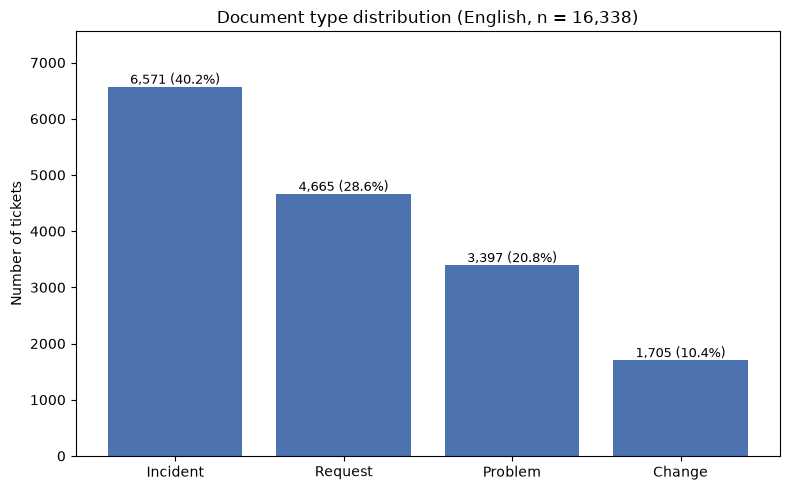

In [19]:
# ===== Cell 4.10: Run E on the document type =====

total_type_tickets = type_distribution["tickets"].sum()
plot_label_distribution(type_distribution, "type",
                        f"Document type distribution (English, n = {total_type_tickets:,})")

## 5. Label distribution: department (`queue`)

In [20]:
# ===== Cell 5.1: Run C on the department =====

department_spelling_problems = check_label_consistency(english_tickets[department_column])

if len(department_spelling_problems) == 0:
    print("OK - every department is written in one way only.")
else:
    print("Problems found:")
    for normalized_label, spellings in department_spelling_problems.items():
        print("  ", normalized_label, "->", spellings)

Missing labels (NaN): 0
OK - every department is written in one way only.


In [21]:
# ===== Cell 5.2: Run D on the department =====

department_config_problems = compare_with_config(english_tickets[department_column], config["data"]["departments"])

if len(department_config_problems) == 0:
    print("OK - the departments in the data match config.yaml exactly.")
department_config_problems

OK - the departments in the data match config.yaml exactly.


,label,status


In [22]:
# ===== Cell 5.3: Run A on the department =====

department_distribution = count_labels(english_tickets[department_column], "queue")
print("Total tickets:", department_distribution["tickets"].sum())
department_distribution

Total tickets: 16338


,queue,tickets,percent
0,Technical Support,4737,29.0
1,Product Support,3073,18.8
2,Customer Service,2410,14.8
3,IT Support,1942,11.9
4,Billing and Payments,1595,9.8
5,Returns and Exchanges,820,5.0
6,Service Outages and Maintenance,664,4.1
7,Sales and Pre-Sales,513,3.1
8,Human Resources,348,2.1
9,General Inquiry,236,1.4


In [23]:
# ===== Cell 5.4: Run B on the department =====

department_imbalance = imbalance_ratio(department_distribution)
smallest_department_percent = department_distribution["percent"].min()
smallest_department_count = department_distribution["tickets"].min()

print("Imbalance ratio (biggest / smallest):", department_imbalance)
print("Smallest class share:", smallest_department_percent, "%")
print("Smallest class size:", smallest_department_count, "tickets")

Imbalance ratio (biggest / smallest): 20.1
Smallest class share: 1.4 %
Smallest class size: 236 tickets


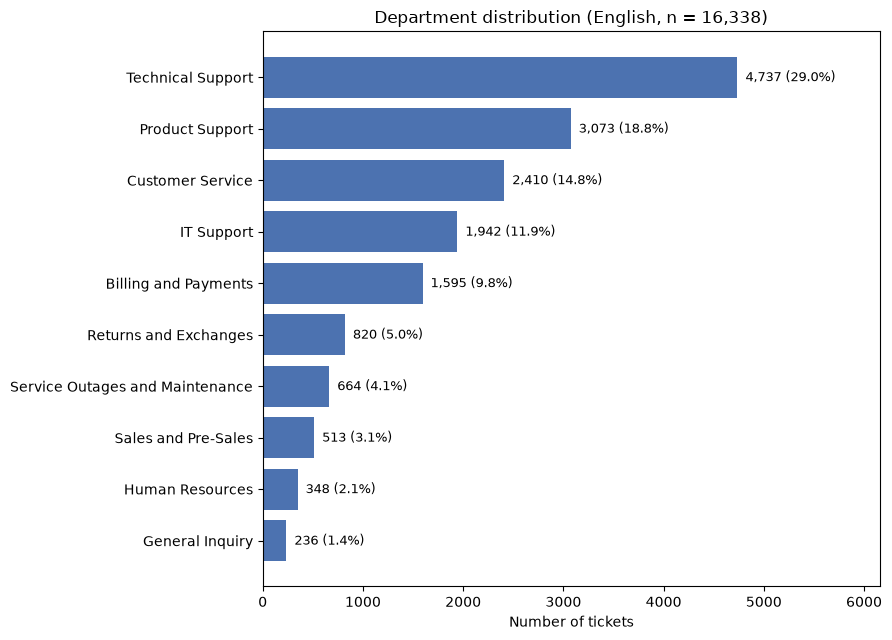

In [24]:
# ===== Cell 5.5: Run E on the department (horizontal: the names are long) =====

total_department_tickets = department_distribution["tickets"].sum()
plot_label_distribution(department_distribution, "queue",
                        f"Department distribution (English, n = {total_department_tickets:,})",
                        orientation="horizontal")

In [25]:
# ===== Cell 5.6: Function F - small_classes_in_test =====

def small_classes_in_test(distribution_table, test_share, minimum_test_count):
    """
    Input : distribution_table - the table returned by count_labels.
            test_share         - share of the data that goes to the test set (e.g. 0.1).
            minimum_test_count - a class with fewer expected test tickets is marked as small.
    Output: a copy of the table with two new columns:
              expected_in_test - tickets * test_share, rounded to a whole number
              small_in_test    - True when expected_in_test < minimum_test_count
    """
    result_table = distribution_table.copy()       # do not change the caller's table

    expected_counts = []
    small_flags = []
    for tickets in result_table["tickets"]:
        expected_in_test = int(round(tickets * test_share))
        expected_counts.append(expected_in_test)
        small_flags.append(expected_in_test < minimum_test_count)

    result_table["expected_in_test"] = expected_counts
    result_table["small_in_test"] = small_flags
    return result_table

In [26]:
# ===== Cell 5.7: Run F on the department =====

test_share = config["data"]["split"]["test"]     # 0.1
minimum_test_count = 50

department_test_sizes = small_classes_in_test(department_distribution, test_share, minimum_test_count)

small_department_count = int(department_test_sizes["small_in_test"].sum())
print("Departments with fewer than", minimum_test_count, "expected test tickets:", small_department_count)
department_test_sizes

Departments with fewer than 50 expected test tickets: 2


,queue,tickets,percent,expected_in_test,small_in_test
0,Technical Support,4737,29.0,474,False
1,Product Support,3073,18.8,307,False
2,Customer Service,2410,14.8,241,False
3,IT Support,1942,11.9,194,False
4,Billing and Payments,1595,9.8,160,False
5,Returns and Exchanges,820,5.0,82,False
6,Service Outages and Maintenance,664,4.1,66,False
7,Sales and Pre-Sales,513,3.1,51,False
8,Human Resources,348,2.1,35,True
9,General Inquiry,236,1.4,24,True


In [27]:
# ===== Cell 5.8: Function G - group_share =====

def group_share(distribution_table, label_name, group_labels):
    """
    Input : distribution_table - the table returned by count_labels.
            label_name         - the label column name in that table.
            group_labels       - list of labels that form the group.
    Output: the sum of the percents of the labels in the group (float, 1 decimal).
    """
    percent_by_label = {}
    for position in range(len(distribution_table)):
        label = distribution_table[label_name].iloc[position]
        percent = distribution_table["percent"].iloc[position]
        percent_by_label[label] = percent

    total_percent = 0.0
    for label in group_labels:
        if label not in percent_by_label:
            raise ValueError(f"'{label}' is not in the table - check the spelling.")
        total_percent = total_percent + percent_by_label[label]

    return round(total_percent, 1)

In [28]:
# ===== Cell 5.9: Run G on the four overlapping departments (OP-1) =====

overlapping_departments = [
    "Technical Support",
    "Product Support",
    "Customer Service",
    "IT Support",
]

overlapping_share = group_share(department_distribution, "queue", overlapping_departments)
print("The four overlapping departments together:", overlapping_share, "% of the English tickets")

The four overlapping departments together: 74.5 % of the English tickets


## 6. Relationships between columns (type, department, priority, missing subject, tags)

In [29]:
# ===== Cell 6.1: How strongly are the label-like columns related? (Cramér's V) =====
# Cramér's V measures the link between two categorical columns:
#   0   = no relation (knowing one tells nothing about the other)
#   1   = full relation (one column decides the other)
# It is built on the chi-square test: compare the real counts with the counts
# we would expect if the two columns were independent.

def cramers_v(first_column, second_column):
    """Cramér's V between two categorical pandas Series of the same length."""
    contingency = pd.crosstab(first_column, second_column)   # real counts, one cell per pair of values

    total = contingency.values.sum()
    row_totals = contingency.sum(axis=1)
    column_totals = contingency.sum(axis=0)

    chi_square = 0.0
    for row_label in contingency.index:
        for column_label in contingency.columns:
            observed = contingency.loc[row_label, column_label]
            expected = row_totals[row_label] * column_totals[column_label] / total   # count if independent
            chi_square = chi_square + (observed - expected) ** 2 / expected

    number_of_row_values = contingency.shape[0]
    number_of_column_values = contingency.shape[1]
    smaller_dimension = min(number_of_row_values, number_of_column_values) - 1
    if smaller_dimension == 0:
        return 0.0

    return (chi_square / (total * smaller_dimension)) ** 0.5


columns_to_compare = [type_column, department_column, "priority", "subject_missing", "tag_1"]

relation_matrix = pd.DataFrame(index=columns_to_compare, columns=columns_to_compare, dtype=float)

for first_name in columns_to_compare:
    for second_name in columns_to_compare:
        if first_name == second_name:
            relation_matrix.loc[first_name, second_name] = 1.0
        else:
            value = cramers_v(english_tickets[first_name], english_tickets[second_name])
            relation_matrix.loc[first_name, second_name] = round(value, 2)

relation_matrix

,type,queue,priority,subject_missing,tag_1
type,1.00,0.19,0.06,0.02,0.44
queue,0.19,1.00,0.28,0.04,0.34
priority,0.06,0.28,1.00,0.01,0.16
subject_missing,0.02,0.04,0.01,1.00,0.15
tag_1,0.44,0.34,0.16,0.15,1.00


In [30]:
# ===== Cell 6.2: Type vs department - share of each type inside each department =====
# Each row adds up to 100%. If the rows look very different, the type says something about the department.

type_by_department_counts = pd.crosstab(english_tickets[department_column], english_tickets[type_column])

type_by_department_percent = type_by_department_counts.copy().astype(float)
for department_name in type_by_department_counts.index:
    department_total = type_by_department_counts.loc[department_name].sum()
    for type_name in type_by_department_counts.columns:
        count = type_by_department_counts.loc[department_name, type_name]
        type_by_department_percent.loc[department_name, type_name] = round(100 * count / department_total, 1)

type_by_department_percent

type,Change,Incident,Problem,Request
queue,,,,
Billing and Payments,6.0,24.2,21.6,48.3
Customer Service,8.1,25.2,21.6,45.1
General Inquiry,28.4,30.1,20.8,20.8
Human Resources,5.7,52.9,10.3,31.0
IT Support,17.4,35.5,25.2,21.9
Product Support,11.4,45.0,21.7,21.9
Returns and Exchanges,12.8,38.9,19.9,28.4
Sales and Pre-Sales,17.5,20.1,12.1,50.3
Service Outages and Maintenance,22.7,55.6,6.6,15.1


## 7. Text length: characters and DistilBERT tokens

Decide `max_length` and `min_text_chars`.

In [31]:
# ===== Cell 7.1: Function A - text_lengths =====

def text_lengths(text_values, unit):
    """
    Input : text_values - a pandas Series of texts (subject or body).
            unit        - "chars" (count characters) or "words" (count words split by spaces).
    Output: a list with one length per text, in the same order as text_values.
            A missing text (NaN) gets length 0 (decision: an empty subject counts as 0).
    """
    if unit != "chars" and unit != "words":
        raise ValueError('unit must be "chars" or "words"')

    lengths = []
    for text in text_values:
        if pd.isna(text):                 # missing subject -> length 0
            lengths.append(0)
            continue

        text = str(text)
        if unit == "chars":
            lengths.append(len(text))
        else:
            words = text.split()          # split on any whitespace, empty pieces are dropped
            lengths.append(len(words))

    return lengths

In [32]:
# ===== Cell 7.2: Function - length_statistics (used by A, C and F) =====

def percentile_from_sorted(sorted_values, share):
    """
    Helper for length_statistics.
    Input : sorted_values - a list sorted from small to big.
            share         - 0.5 for the median, 0.95 for p95.
    Output: the value at that position. When the position falls between two values,
            we take a straight line between them (same rule as numpy / pandas).
    """
    position = share * (len(sorted_values) - 1)
    lower_index = int(position)                    # whole part of the position
    upper_index = lower_index + 1
    if upper_index >= len(sorted_values):          # position is exactly the last value
        return float(sorted_values[lower_index])

    fraction = position - lower_index              # how far we are between the two values
    lower_value = sorted_values[lower_index]
    upper_value = sorted_values[upper_index]
    return lower_value + fraction * (upper_value - lower_value)


def length_statistics(lengths):
    """
    Input : lengths - a list of numbers (characters, words or tokens).
    Output: a dict with mean, variance, median, p95 and max.
            Variance uses (n - 1) in the bottom, the same as pandas .var().
    """
    if len(lengths) == 0:
        raise ValueError("lengths is empty: nothing to describe")

    # Step 1: mean
    total = 0
    for value in lengths:
        total = total + value
    count = len(lengths)
    mean = total / count

    # Step 2: variance = average squared distance from the mean
    squared_distance_sum = 0
    for value in lengths:
        squared_distance_sum = squared_distance_sum + (value - mean) ** 2
    if count > 1:
        variance = squared_distance_sum / (count - 1)
    else:
        variance = 0.0                             # one value: no spread

    # Step 3: median, p95 and max need the values sorted
    sorted_lengths = sorted(lengths)
    median = percentile_from_sorted(sorted_lengths, 0.5)
    p95 = percentile_from_sorted(sorted_lengths, 0.95)
    maximum = sorted_lengths[-1]

    return {
        "mean": round(mean, 1),
        "variance": round(variance, 1),
        "median": round(median, 1),
        "p95": round(p95, 1),
        "max": maximum,
    }

In [33]:
# ===== Cell 7.3: Run A - characters and words for subject and body =====

subject_column = "subject"
body_column = "body"

length_rows = []
for column_name in [subject_column, body_column]:
    for unit in ["chars", "words"]:
        lengths = text_lengths(english_tickets[column_name], unit)
        row = {"column": column_name, "unit": unit}
        statistics = length_statistics(lengths)
        for statistic_name in statistics:
            row[statistic_name] = statistics[statistic_name]
        length_rows.append(row)

length_table = pd.DataFrame(length_rows)
length_table

,column,unit,mean,variance,median,p95,max
0,subject,chars,36.7,457.6,39.0,69.0,234
1,subject,words,4.8,8.0,5.0,9.0,29
2,body,chars,367.9,32358.9,377.0,604.0,1147
3,body,words,53.9,725.4,55.0,90.0,168


In [34]:
# ===== Cell 7.4: Function B - find_short_texts =====

def find_short_texts(text_values, min_chars, max_examples):
    """
    Input : text_values  - a pandas Series of texts.
            min_chars    - a text with fewer characters than this is "short".
            max_examples - how many examples to show at most.
    Output: (short_count, examples_table)
              short_count    - how many texts are short (all of them, not only the shown ones)
              examples_table - up to max_examples rows: row, text, length
            A missing text (NaN) counts as length 0, so it is short.
    """
    short_count = 0
    example_rows = []

    for row_number, text in text_values.items():   # row_number = index in the DataFrame
        if pd.isna(text):
            text = ""
        text = str(text)
        text_length = len(text)

        if text_length < min_chars:
            short_count = short_count + 1
            if len(example_rows) < max_examples:
                example_rows.append({"row": row_number, "text": text, "length": text_length})

    examples_table = pd.DataFrame(example_rows, columns=["row", "text", "length"])
    return short_count, examples_table

In [35]:
# ===== Cell 7.5: Run B - joined texts shorter than min_text_chars =====
# FR-2: subject and body are joined into one text, and min_text_chars is checked
# on that joined text. So we measure the same thing preprocess.py will drop.
# A missing subject -> the body alone (no ". " at the start).

text_separator = config["data"]["text_separator"]               # ". "
min_text_chars = config["data"]["cleaning"]["min_text_chars"]   # 10
max_short_examples = 10

joined_texts = []
subject_list = list(english_tickets[subject_column])
body_list = list(english_tickets[body_column])
for position in range(len(subject_list)):
    subject = subject_list[position]
    body = body_list[position]
    if pd.isna(body):
        body = ""
    if pd.isna(subject) or str(subject) == "":
        joined_texts.append(str(body))
    else:
        joined_texts.append(str(subject) + text_separator + str(body))

joined_text_series = pd.Series(joined_texts, index=english_tickets.index)

short_text_count, short_text_examples = find_short_texts(
    joined_text_series, min_text_chars, max_short_examples)

print("Joined texts (subject + body) shorter than", min_text_chars, "characters:",
      short_text_count, "of", len(english_tickets))
short_text_examples

Joined texts (subject + body) shorter than 10 characters: 0 of 16338


,row,text,length


In [36]:
# ===== Cell 7.6: Load the DistilBERT tokenizer =====
# Needs internet the first time (downloads from Hugging Face), then it is cached.
# Only the tokenizer is loaded here, not the model.

from transformers import AutoTokenizer

tokenizer_name = config["transformer"]["model_name"]     # distilbert-base-uncased
tokenizer = AutoTokenizer.from_pretrained(tokenizer_name)

print("Tokenizer:", tokenizer_name)
print("Largest input the model accepts:", tokenizer.model_max_length, "tokens")

c:\Users\mohme\projedcts\NHA-5-168\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Tokenizer: distilbert-base-uncased
Largest input the model accepts: 512 tokens


In [37]:
# ===== Cell 7.7: Function C - compute_token_lengths =====

def compute_token_lengths(subject_values, body_values, tokenizer):
    """
    Input : subject_values - a pandas Series of subjects (may contain NaN).
            body_values    - a pandas Series of bodies, same length and order.
            tokenizer      - a Hugging Face tokenizer.
    Output: a list with the number of tokens for each ticket, in the same order.
    How   : two segments, the same form the model will see:
                [CLS] subject [SEP] body [SEP]
            No truncation, so we get the real length (a warning about
            "longer than 512" is expected and harmless here: nothing is sent to the model).
            A missing subject becomes "" (DEC-7): [CLS] [SEP] body [SEP]
    """
    if len(subject_values) != len(body_values):
        raise ValueError("subject_values and body_values must have the same length")

    subject_list = list(subject_values)
    body_list = list(body_values)

    token_lengths = []
    for position in range(len(subject_list)):
        subject = subject_list[position]
        body = body_list[position]
        if pd.isna(subject):
            subject = ""
        if pd.isna(body):
            body = ""

        encoded = tokenizer(str(subject), str(body), add_special_tokens=True, truncation=False)
        token_lengths.append(len(encoded["input_ids"]))

    return token_lengths

In [38]:
# ===== Cell 7.8: Run C - token length of every English ticket =====
# Saved as a temporary column (like subject_missing in 3.2), so each length
# stays with its own row even if english_tickets is filtered or sorted later.
# For EDA only: this column never reaches the model (cleaning lives in src/preprocess.py).

token_length_column = "token_length"
english_tickets[token_length_column] = compute_token_lengths(english_tickets[subject_column],
                                                             english_tickets[body_column],
                                                             tokenizer)

print("Tickets measured:", len(english_tickets))
token_statistics = length_statistics(list(english_tickets[token_length_column]))
pd.DataFrame([token_statistics], index=["tokens (subject + body)"])

Tickets measured: 16338


,mean,variance,median,p95,max
tokens (subject + body),74.3,1099.7,76.0,121.0,234


In [39]:
# ===== Cell 7.9: Function D - truncation_share =====

def truncation_share(token_lengths, candidate_max_lengths):
    """
    Input : token_lengths         - list of token counts (from compute_token_lengths).
            candidate_max_lengths - list of max_length values to test, e.g. [64, 128, 256, 512].
    Output: a table with one row per candidate:
              max_length - the candidate
              truncated  - how many tickets are longer than it (they would be cut)
              percent    - truncated / all tickets * 100
    """
    if len(token_lengths) == 0:
        raise ValueError("token_lengths is empty")

    total_tickets = len(token_lengths)
    rows = []
    for max_length in candidate_max_lengths:
        truncated_count = 0
        for length in token_lengths:
            if length > max_length:
                truncated_count = truncated_count + 1
        rows.append({
            "max_length": max_length,
            "truncated": truncated_count,
            "percent": round(truncated_count / total_tickets * 100, 1),
        })

    return pd.DataFrame(rows)

In [40]:
# ===== Cell 7.10: Run D - how many tickets are cut at each max_length =====

candidate_max_lengths = [64, 128, 256, 512]

truncation_table = truncation_share(list(english_tickets[token_length_column]), candidate_max_lengths)
truncation_table

,max_length,truncated,percent
0,64,9749,59.7
1,128,352,2.2
2,256,0,0.0
3,512,0,0.0


In [41]:
# ===== Cell 7.11: Function E - plot_token_length_histogram =====

def plot_token_length_histogram(token_lengths, line_positions, title):
    """
    Input : token_lengths  - list of token counts.
            line_positions - list of x values to mark with a dashed line (the candidates).
            title          - chart title.
    Output: none - shows a histogram with one labeled dashed line per position.
    """
    line_colors = ["#55A868", "#C44E52", "#8172B2", "#CCB974", "#64B5CD"]

    figure, axis = plt.subplots(figsize=(10, 5))
    axis.hist(token_lengths, bins=60, color="#4C72B0", edgecolor="white")

    for position in range(len(line_positions)):
        x_value = line_positions[position]
        color = line_colors[position % len(line_colors)]
        axis.axvline(x_value, color=color, linestyle="--", linewidth=1.5,
                     label=f"max_length = {x_value}")

    axis.set_xlabel("Tokens per ticket ([CLS] subject [SEP] body [SEP])")
    axis.set_ylabel("Number of tickets")
    axis.set_title(title)
    axis.legend()
    plt.tight_layout()
    plt.show()

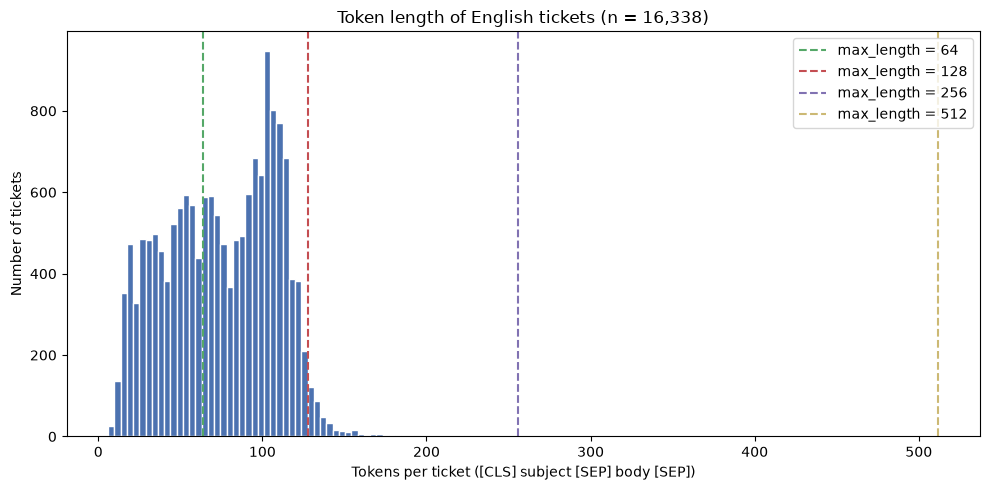

In [42]:
# ===== Cell 7.12: Run E - token length histogram =====

plot_token_length_histogram(list(english_tickets[token_length_column]), candidate_max_lengths,
                            f"Token length of English tickets (n = {len(english_tickets):,})")

In [43]:
# ===== Cell 7.13: Function F - token_length_by_group =====

def token_length_by_group(token_lengths, group_values, max_length):
    """
    Input : token_lengths - list of token counts, same order as group_values.
            group_values  - a pandas Series with the group of each ticket (e.g. queue).
            max_length    - tickets longer than this count as truncated.
    Output: a table with one row per group, biggest mean first:
              group, tickets, mean, median, p95, max, truncated_%
            Uses length_statistics for the numbers.
    """
    if len(token_lengths) != len(group_values):
        raise ValueError("token_lengths and group_values must have the same length")

    # Step 1: collect the lengths of each group in a dict {group: [lengths]}
    lengths_by_group = {}
    group_list = list(group_values)
    for position in range(len(group_list)):
        group = group_list[position]
        if group not in lengths_by_group:
            lengths_by_group[group] = []
        lengths_by_group[group].append(token_lengths[position])

    # Step 2: statistics and truncation share for each group
    rows = []
    for group in lengths_by_group:
        group_lengths = lengths_by_group[group]
        statistics = length_statistics(group_lengths)

        truncated_count = 0
        for length in group_lengths:
            if length > max_length:
                truncated_count = truncated_count + 1

        rows.append({
            "group": group,
            "tickets": len(group_lengths),
            "mean": statistics["mean"],
            "median": statistics["median"],
            "p95": statistics["p95"],
            "max": statistics["max"],
            "truncated_%": round(truncated_count / len(group_lengths) * 100, 1),
        })

    result_table = pd.DataFrame(rows)
    result_table = result_table.sort_values("mean", ascending=False).reset_index(drop=True)
    return result_table

In [44]:
# ===== Cell 7.14: Run F - token length per department =====
# max_length comes from config.yaml (256 now). After the decision from D (7.10),
# update config.yaml and re-run: F then uses the chosen value automatically.

group_max_length = config["transformer"]["max_length"]

department_token_lengths = token_length_by_group(list(english_tickets[token_length_column]),
                                                 english_tickets[department_column],
                                                 group_max_length)
print("Truncated = longer than", group_max_length, "tokens")
department_token_lengths

Truncated = longer than 256 tokens


,group,tickets,mean,median,p95,max,truncated_%
0,General Inquiry,236,79.0,89.5,121.0,131,0.0
1,Technical Support,4737,75.4,77.0,121.0,193,0.0
2,Billing and Payments,1595,74.8,77.0,121.0,234,0.0
3,IT Support,1942,74.0,74.0,121.0,186,0.0
4,Customer Service,2410,74.0,75.0,121.0,224,0.0
5,Service Outages and Maintenance,664,73.7,78.0,122.0,186,0.0
6,Product Support,3073,73.7,74.0,122.0,207,0.0
7,Returns and Exchanges,820,72.7,74.5,120.0,224,0.0
8,Sales and Pre-Sales,513,72.4,75.0,119.0,147,0.0
9,Human Resources,348,71.4,70.0,121.6,157,0.0


## 8. Duplicate tickets

## 9. Overlapping departments: read examples

Technical Support, Product Support, Customer Service, IT Support.

## 10. Reference baselines (majority class, most-frequent top-3)

## 11. Findings and decisions for `config.yaml`